In [1]:
!pip install catboost xgboost lightgbm gradio

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 57.6 MB/s  0:00:01


In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import LabelEncoder, StandardScaler

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    balanced_accuracy_score,
    roc_auc_score,roc_curve,
    precision_recall_curve,average_precision_score
)
# Classification models
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

from sklearn.naive_bayes import GaussianNB

from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    AdaBoostClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier,
    VotingClassifier,
    StackingClassifier
)

from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier

In [3]:
df = pd.read_csv('bank.csv')

In [4]:
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
0,59,admin.,married,secondary,no,2343.0,yes,no,unknown,5.0,may,1042.0,1.0,-1.0,0.0,unknown,yes
1,56,admin.,married,secondary,no,45.0,no,no,unknown,5.0,may,1467.0,1.0,-1.0,0.0,unknown,yes
2,41,technician,married,secondary,no,1270.0,yes,no,unknown,5.0,may,1389.0,1.0,-1.0,0.0,unknown,yes
3,54,admin.,married,tertiary,no,184.0,no,no,unknown,5.0,may,673.0,2.0,-1.0,0.0,unknown,yes
4,42,management,single,tertiary,no,0.0,yes,yes,unknown,5.0,may,562.0,2.0,-1.0,0.0,unknown,yes


In [5]:
df.shape

(8912, 17)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8912 entries, 0 to 8911
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   age        8912 non-null   int64  
 1   job        8905 non-null   object 
 2   marital    8743 non-null   object 
 3   education  8885 non-null   object 
 4   default    8908 non-null   object 
 5   balance    8899 non-null   float64
 6   housing    8899 non-null   object 
 7   loan       8882 non-null   object 
 8   contact    8881 non-null   object 
 9   day        8893 non-null   float64
 10  month      8884 non-null   object 
 11  duration   8905 non-null   float64
 12  campaign   8904 non-null   float64
 13  pdays      8767 non-null   float64
 14  previous   8909 non-null   float64
 15  poutcome   8912 non-null   object 
 16  deposit    8903 non-null   object 
dtypes: float64(6), int64(1), object(10)
memory usage: 1.2+ MB


In [7]:
df.describe()

,age,balance,day,duration,campaign,pdays,previous
count,8912.000000,8899.000000,8893.000000,8905.000000,8904.000000,8767.000000,8909.000000
mean,41.257855,1539.680638,15.684921,374.953734,2.512579,52.456941,0.834325
std,11.840567,3297.446702,8.406729,351.283501,2.772366,109.094161,2.304733
min,18.000000,-3058.000000,1.000000,3.000000,1.000000,-1.000000,0.000000
25%,32.000000,121.500000,8.000000,139.000000,1.000000,-1.000000,0.000000
50%,39.000000,553.000000,15.000000,256.000000,2.000000,-1.000000,0.000000
75%,49.000000,1726.000000,22.000000,501.000000,3.000000,64.000000,1.000000
max,95.000000,81204.000000,31.000000,3284.000000,63.000000,842.000000,58.000000


In [8]:
df.columns

Index(['age', 'job', 'marital', 'education', 'default', 'balance', 'housing',
       'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays',
       'previous', 'poutcome', 'deposit'],
      dtype='object')

In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
df = df.drop_duplicates()

In [11]:
df.isnull().sum()

,0
age,0
job,7
marital,169
education,27
default,4
balance,13
housing,13
loan,30
contact,31
day,19


In [12]:
df = df.dropna(subset=['deposit'])

In [13]:
X = df.drop(columns=['deposit'])
y = df['deposit']

In [14]:
cat_cols = X.select_dtypes(include=['object']).columns
num_cols = X.select_dtypes(include=['number']).columns

In [15]:
for col in cat_cols:
    X[col] = X[col].fillna(X[col].mode()[0] if not X[col].mode().empty else 'unknown')

In [16]:
for col in num_cols:
    X[col] = X[col].fillna(X[col].median())

In [17]:
X.isnull().sum()

,0
age,0
job,0
marital,0
education,0
default,0
balance,0
housing,0
loan,0
contact,0
day,0


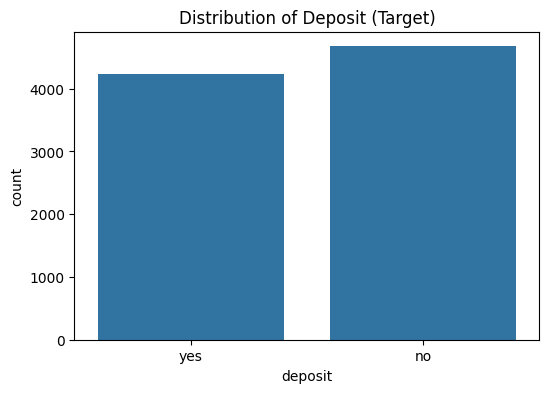

In [18]:
plt.figure(figsize=(6, 4))
sns.countplot(x=y)
plt.title('Distribution of Deposit (Target)')
plt.show()

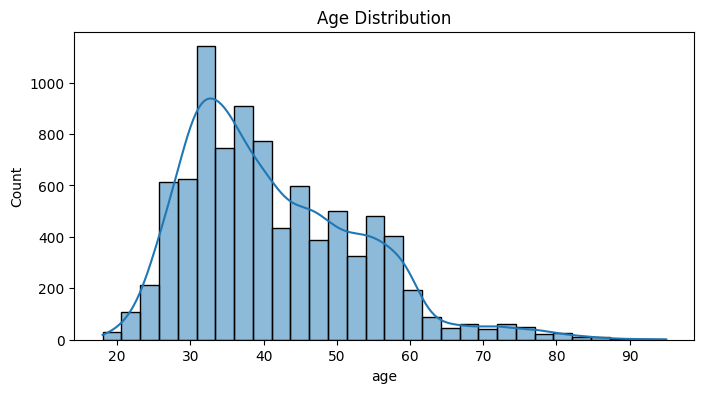

In [19]:
plt.figure(figsize=(8, 4))
sns.histplot(X['age'], kde=True, bins=30)
plt.title('Age Distribution')
plt.show()

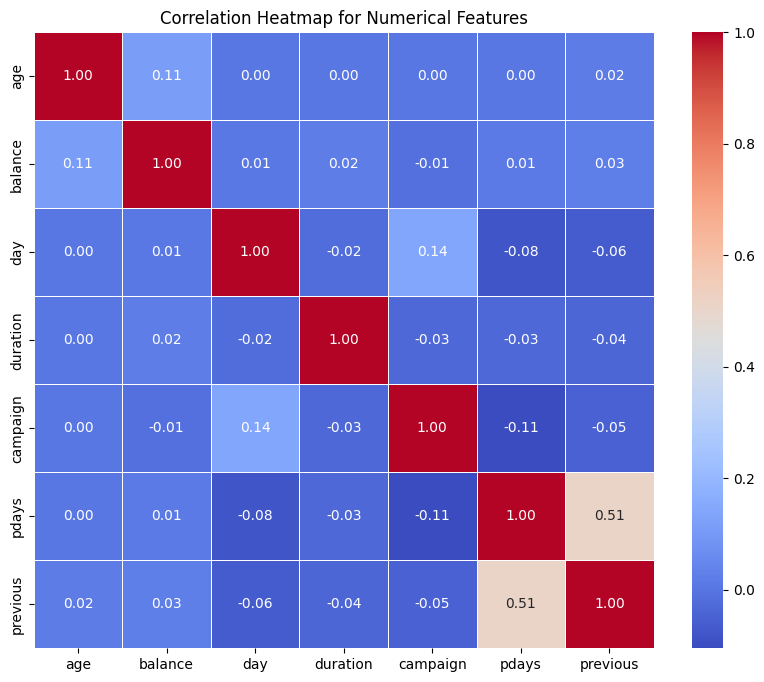

In [20]:
plt.figure(figsize=(10, 8))
numeric_df = X.select_dtypes(include=['number'])
sns.heatmap(numeric_df.corr(), annot=True, fmt='.2f', cmap='coolwarm', linewidths=0.5)
plt.title('Correlation Heatmap for Numerical Features')
plt.show()

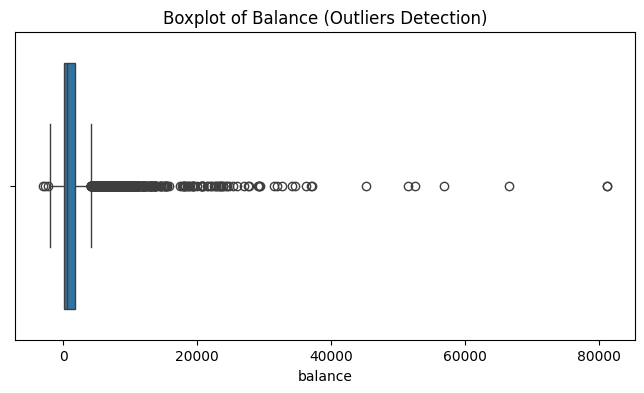

In [21]:
plt.figure(figsize=(8, 4))
sns.boxplot(x=X['balance'])
plt.title('Boxplot of Balance (Outliers Detection)')
plt.show()

In [24]:
le = LabelEncoder()
y_encoded = le.fit_transform(y)
X_encoded = pd.get_dummies(X, columns=cat_cols, drop_first=True)

print("Shape after encoding:", X_encoded.shape)

Shape after encoding: (8903, 42)


In [25]:
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y_encoded, test_size=0.2, random_state=42
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

X_train shape: (7122, 42)
X_test shape: (1781, 42)


In [26]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [27]:
print("Class distribution in y_train:", np.bincount(y_train))

Class distribution in y_train: [3727 3395]


In [28]:

models = {
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'KNN': KNeighborsClassifier(),
    'Naive Bayes': GaussianNB()
}

results = []

for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)

    acc = accuracy_score(y_test, y_pred)
    cm = confusion_matrix(y_test, y_pred)

    results.append({
        'Model': name,
        'Accuracy': f"{acc*100:.2f}%"
    })

    print(f"=== {name} ===")
    print(f"Accuracy: {acc:.4f}")
    print("Confusion Matrix:\n", cm)
    print("Classification Report:\n", classification_report(y_test, y_pred))
    print("-" * 40)


metrics_table = pd.DataFrame(results)
print("\n--- Final Metrics Table ---")
print(metrics_table)

=== Logistic Regression ===
Accuracy: 0.8282
Confusion Matrix:
 [[808 138]
 [168 667]]
Classification Report:
               precision    recall  f1-score   support

           0       0.83      0.85      0.84       946
           1       0.83      0.80      0.81       835

    accuracy                           0.83      1781
   macro avg       0.83      0.83      0.83      1781
weighted avg       0.83      0.83      0.83      1781

----------------------------------------
=== KNN ===
Accuracy: 0.7805
Confusion Matrix:
 [[779 167]
 [224 611]]
Classification Report:
               precision    recall  f1-score   support

           0       0.78      0.82      0.80       946
           1       0.79      0.73      0.76       835

    accuracy                           0.78      1781
   macro avg       0.78      0.78      0.78      1781
weighted avg       0.78      0.78      0.78      1781

----------------------------------------
=== Naive Bayes ===
Accuracy: 0.7120
Confusion Matrix:
 [[

In [29]:
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV
svc_model = SVC(C=1, kernel='rbf', gamma='scale')
svc_model.fit(X_train_scaled, y_train)

grid_params = {'C': [0.1, 1, 10], 'kernel': ['linear', 'rbf']}
grid = GridSearchCV(estimator=SVC(), param_grid=grid_params, cv=3, scoring='accuracy')
grid.fit(X_train_scaled, y_train)

best_svc = grid.best_estimator_
print("Best SVC Accuracy:", accuracy_score(y_test, best_svc.predict(X_test_scaled)))

Best SVC Accuracy: 0.8439079169006176


In [30]:
models = {

    # Linear
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=1),

    # Distance-based
    "KNN": KNeighborsClassifier(n_neighbors=5),

    # SVM
    "SVC": SVC(probability=True, random_state=1),

    # Tree
    "Decision Tree": DecisionTreeClassifier(random_state=1),

    # Naive Bayes
    "Naive Bayes": GaussianNB(),

    # Bagging Based
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=1),
    "Extra Trees": ExtraTreesClassifier(n_estimators=100, random_state=1),

    # Boosting
    "AdaBoost": AdaBoostClassifier(random_state=1),
    "Gradient Boosting": GradientBoostingClassifier(random_state=1),
    "Hist Gradient Boosting": HistGradientBoostingClassifier(random_state=1),

    # External Boosting Libraries
    "XGBoost": XGBClassifier(eval_metric='logloss', random_state=1, use_label_encoder=False),
    "CatBoost": CatBoostClassifier(verbose=0, random_state=1),
    "LightGBM": LGBMClassifier(random_state=1)
}

  0%|          | 0/13 [00:00<?, ?it/s]


Confusion Matrix:
 [[804 142]
 [159 676]]


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


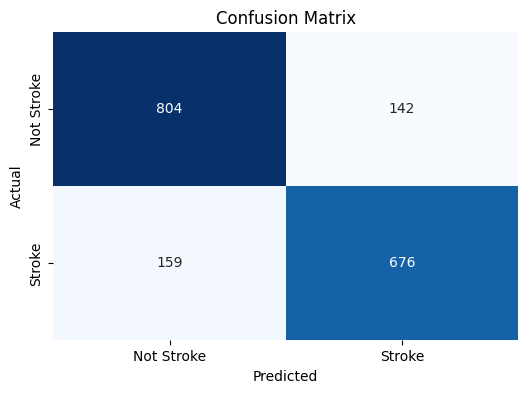


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.83      0.85      0.84       946
      Stroke       0.83      0.81      0.82       835

    accuracy                           0.83      1781
   macro avg       0.83      0.83      0.83      1781
weighted avg       0.83      0.83      0.83      1781

ROC-AUC: 0.9042992239622236


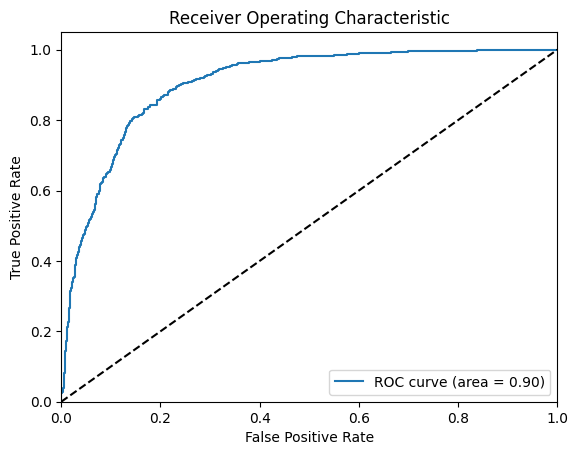

PR AUC: 0.8704940094003285


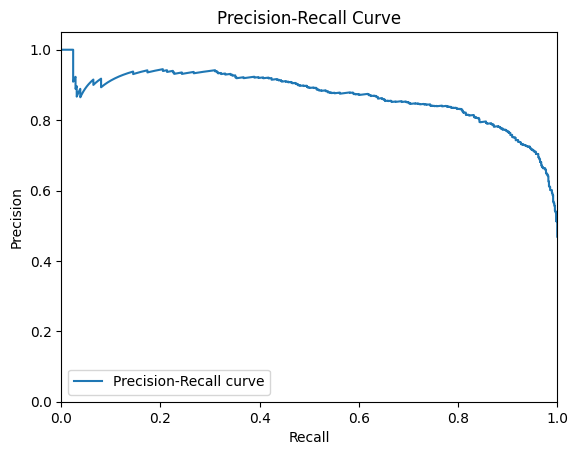

  8%|▊         | 1/13 [00:05<01:00,  5.00s/it]


Confusion Matrix:
 [[724 222]
 [232 603]]


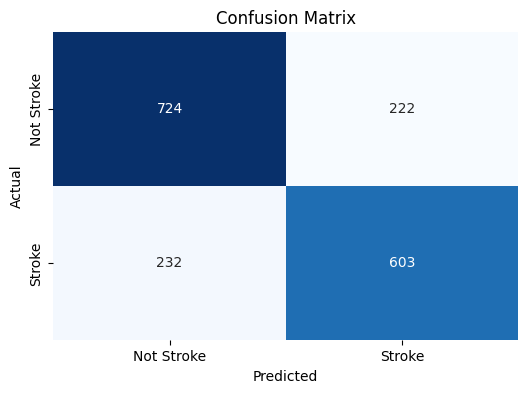


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.76      0.77      0.76       946
      Stroke       0.73      0.72      0.73       835

    accuracy                           0.75      1781
   macro avg       0.74      0.74      0.74      1781
weighted avg       0.74      0.75      0.74      1781

ROC-AUC: 0.8043270752364193


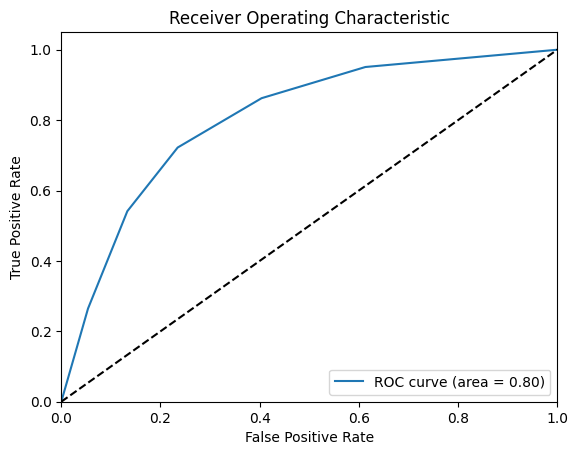

PR AUC: 0.7293428575938834


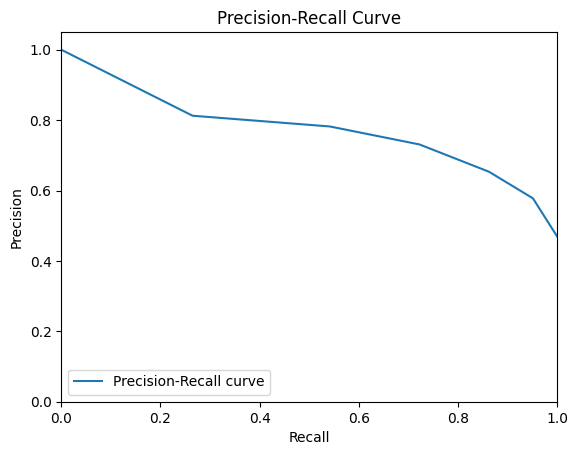

 15%|█▌        | 2/13 [00:05<00:28,  2.56s/it]


Confusion Matrix:
 [[791 155]
 [310 525]]


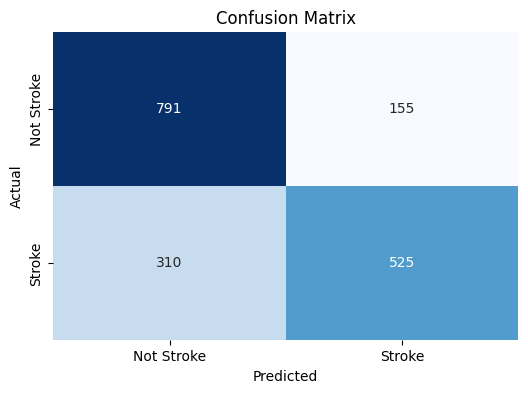


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.72      0.84      0.77       946
      Stroke       0.77      0.63      0.69       835

    accuracy                           0.74      1781
   macro avg       0.75      0.73      0.73      1781
weighted avg       0.74      0.74      0.74      1781

ROC-AUC: 0.8233558253471915


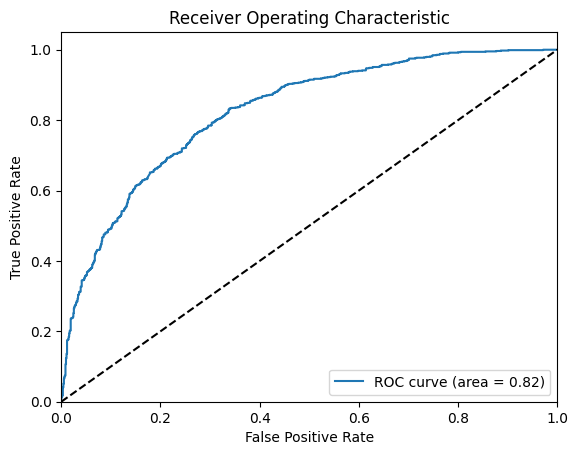

PR AUC: 0.7930578172747671


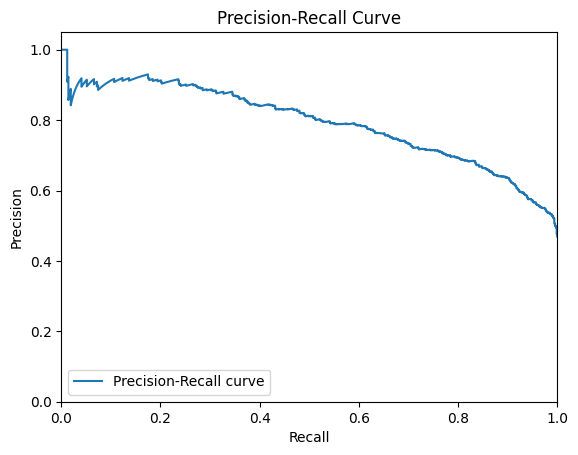

 23%|██▎       | 3/13 [00:25<01:42, 10.23s/it]


Confusion Matrix:
 [[738 208]
 [180 655]]


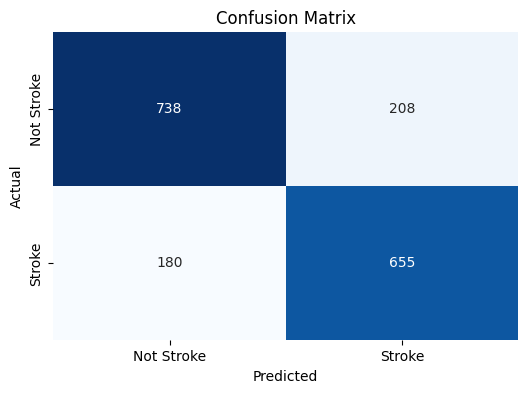


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.80      0.78      0.79       946
      Stroke       0.76      0.78      0.77       835

    accuracy                           0.78      1781
   macro avg       0.78      0.78      0.78      1781
weighted avg       0.78      0.78      0.78      1781

ROC-AUC: 0.7822789938094213


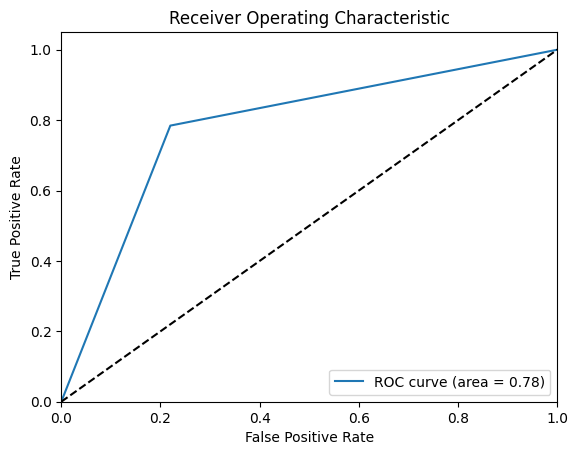

PR AUC: 0.6964345976346589


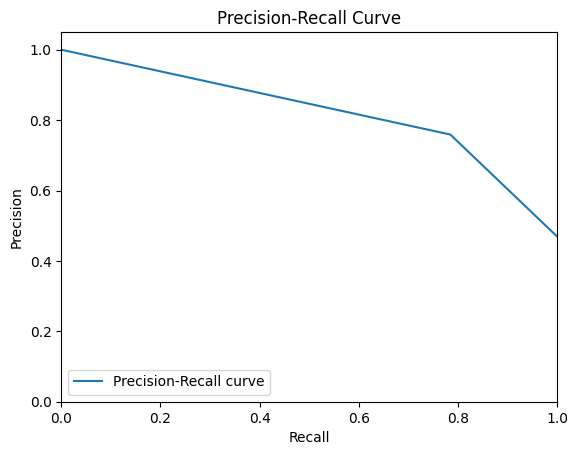

 31%|███       | 4/13 [00:25<00:57,  6.37s/it]


Confusion Matrix:
 [[822 124]
 [363 472]]


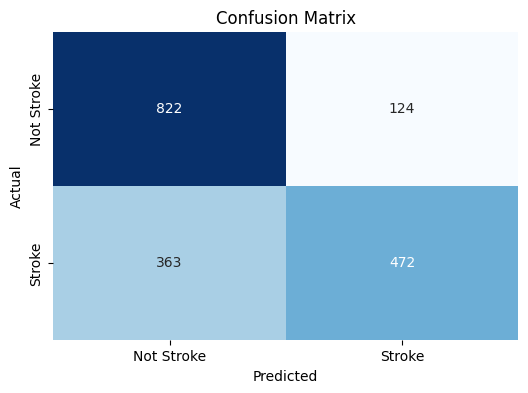


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.69      0.87      0.77       946
      Stroke       0.79      0.57      0.66       835

    accuracy                           0.73      1781
   macro avg       0.74      0.72      0.72      1781
weighted avg       0.74      0.73      0.72      1781

ROC-AUC: 0.8088883543694851


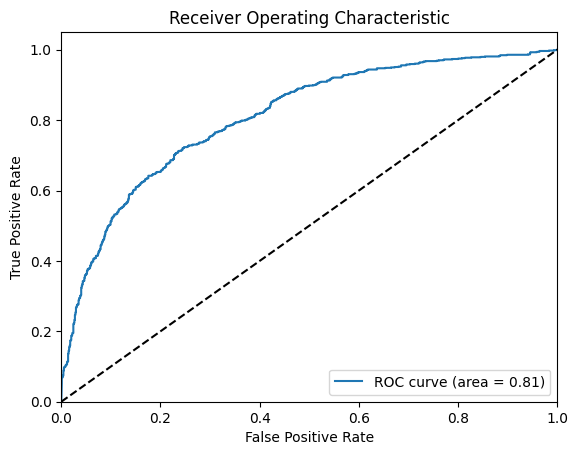

PR AUC: 0.7870658146334186


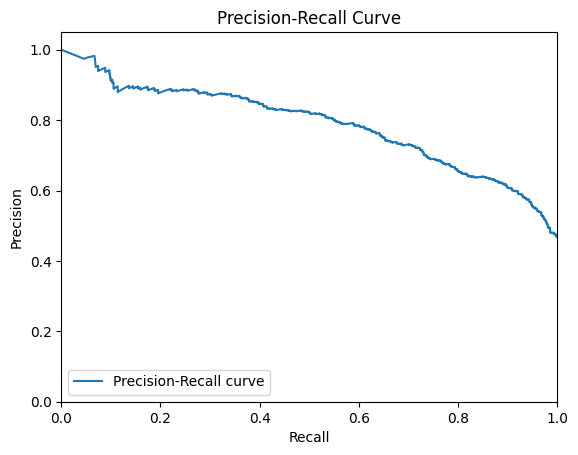

 38%|███▊      | 5/13 [00:26<00:33,  4.22s/it]


Confusion Matrix:
 [[785 161]
 [101 734]]


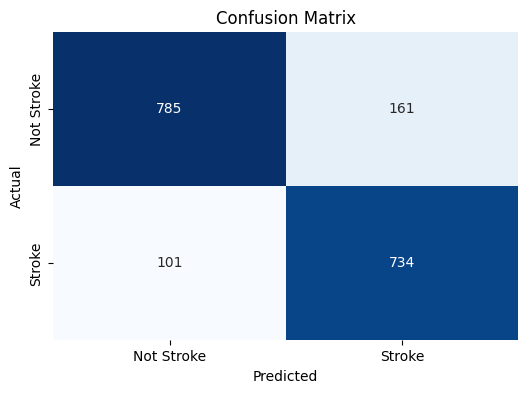


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.89      0.83      0.86       946
      Stroke       0.82      0.88      0.85       835

    accuracy                           0.85      1781
   macro avg       0.85      0.85      0.85      1781
weighted avg       0.86      0.85      0.85      1781

ROC-AUC: 0.9202655998784671


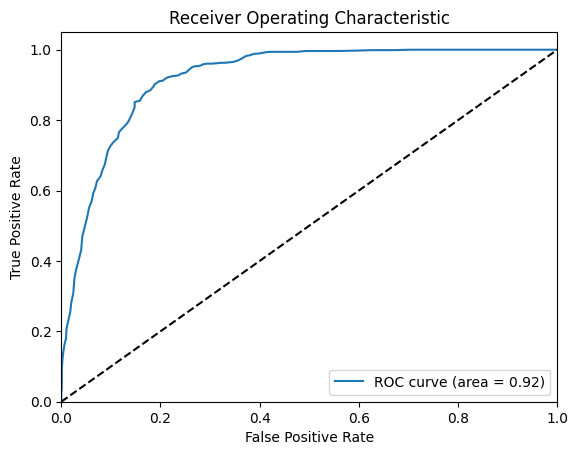

PR AUC: 0.8884991543182006


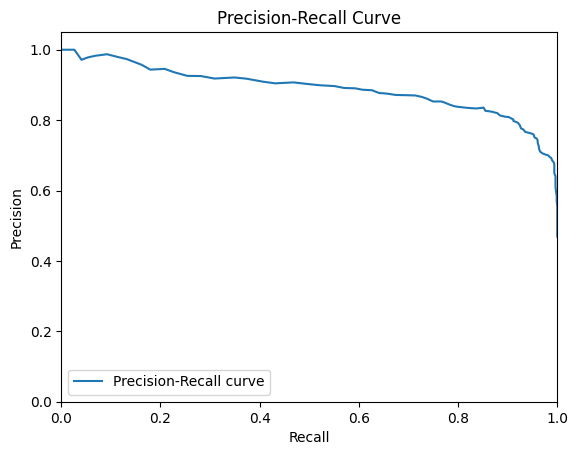

 46%|████▌     | 6/13 [00:27<00:23,  3.39s/it]


Confusion Matrix:
 [[776 170]
 [133 702]]


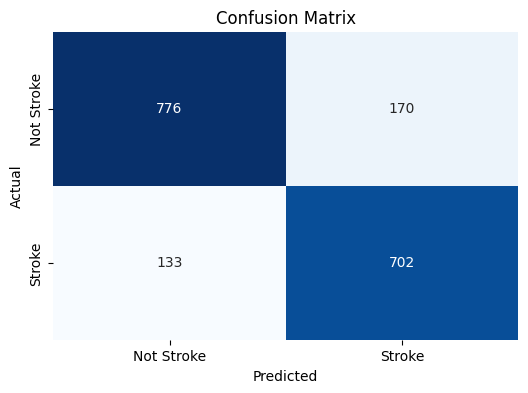


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.85      0.82      0.84       946
      Stroke       0.81      0.84      0.82       835

    accuracy                           0.83      1781
   macro avg       0.83      0.83      0.83      1781
weighted avg       0.83      0.83      0.83      1781

ROC-AUC: 0.9016628476661898


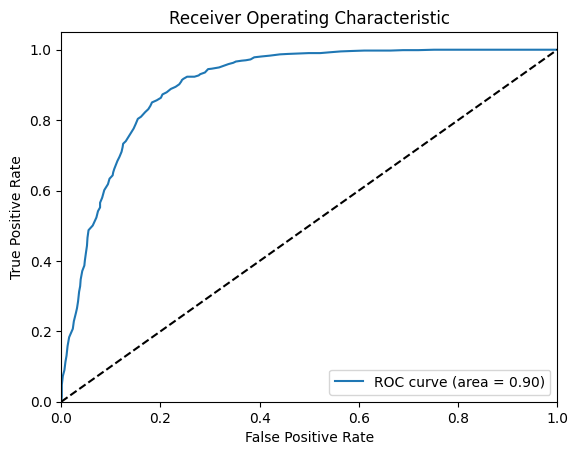

PR AUC: 0.8558758575333936


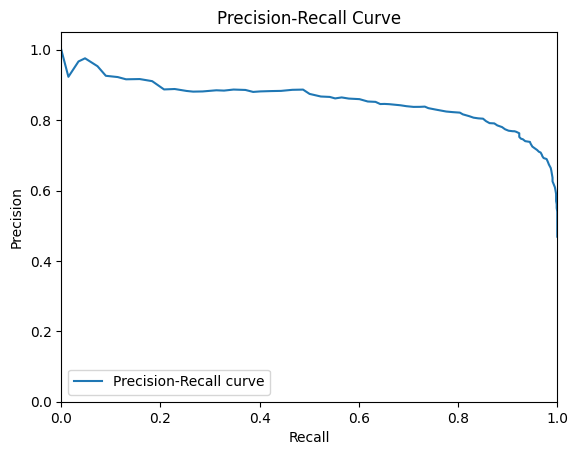

 54%|█████▍    | 7/13 [00:30<00:18,  3.04s/it]


Confusion Matrix:
 [[786 160]
 [198 637]]


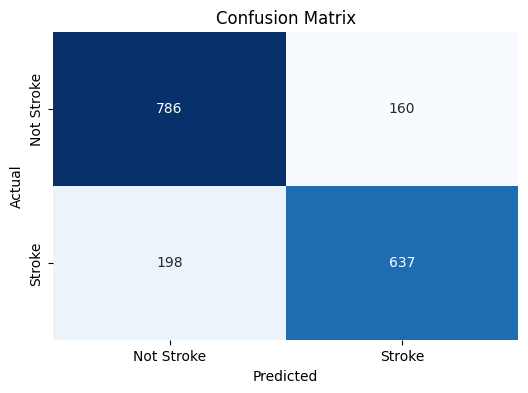


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.80      0.83      0.81       946
      Stroke       0.80      0.76      0.78       835

    accuracy                           0.80      1781
   macro avg       0.80      0.80      0.80      1781
weighted avg       0.80      0.80      0.80      1781

ROC-AUC: 0.886461748806826


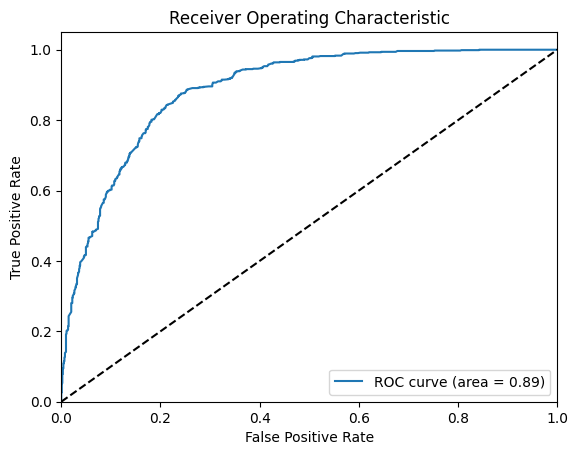

PR AUC: 0.8549277879914092


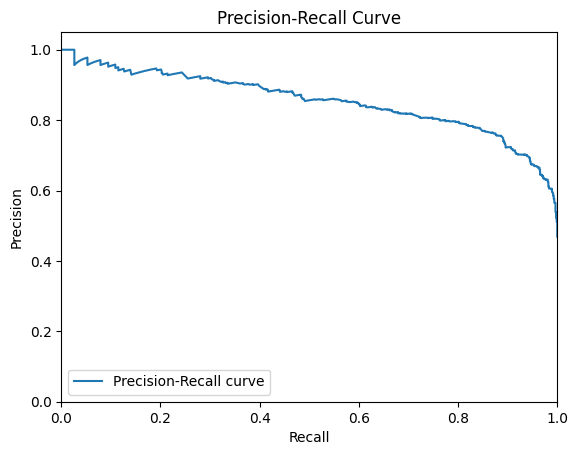

 62%|██████▏   | 8/13 [00:31<00:11,  2.34s/it]


Confusion Matrix:
 [[783 163]
 [119 716]]


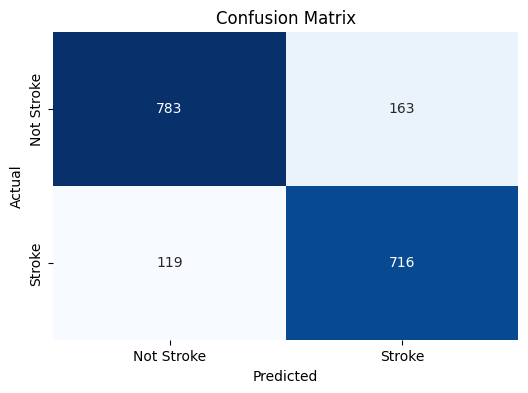


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.87      0.83      0.85       946
      Stroke       0.81      0.86      0.84       835

    accuracy                           0.84      1781
   macro avg       0.84      0.84      0.84      1781
weighted avg       0.84      0.84      0.84      1781

ROC-AUC: 0.9167234241875657


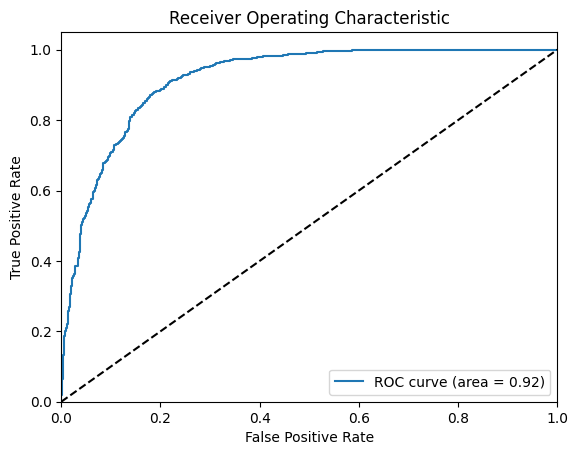

PR AUC: 0.8878664880002066


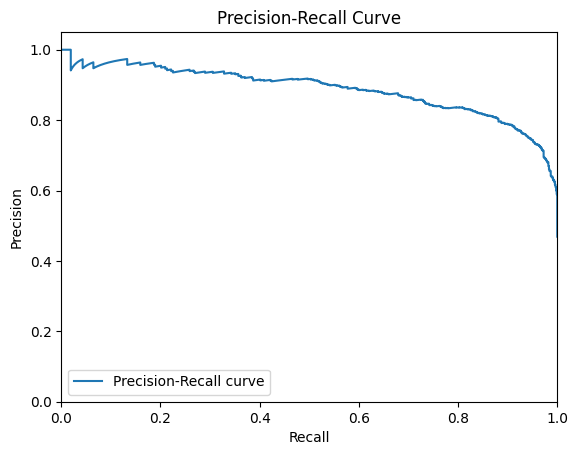

 69%|██████▉   | 9/13 [00:32<00:08,  2.15s/it]


Confusion Matrix:
 [[791 155]
 [ 94 741]]


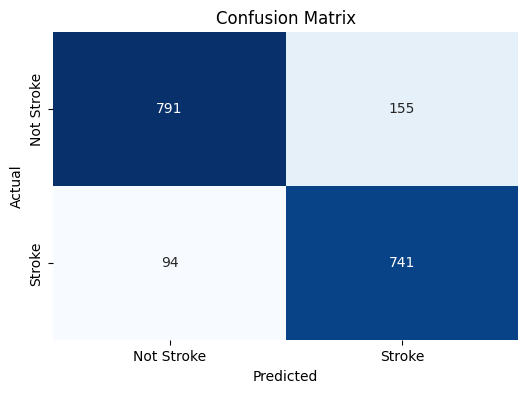


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.89      0.84      0.86       946
      Stroke       0.83      0.89      0.86       835

    accuracy                           0.86      1781
   macro avg       0.86      0.86      0.86      1781
weighted avg       0.86      0.86      0.86      1781

ROC-AUC: 0.9259472598144093


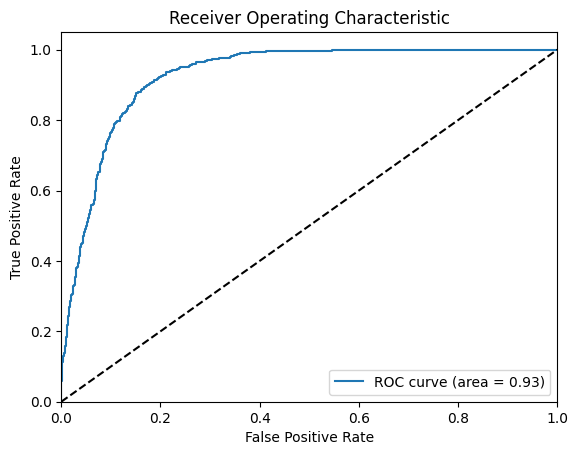

PR AUC: 0.8947275787650241


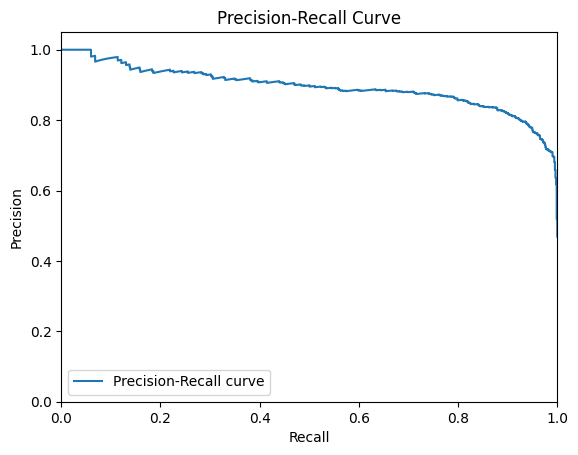

 77%|███████▋  | 10/13 [00:33<00:05,  1.81s/it]/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [15:25:01] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)



Confusion Matrix:
 [[783 163]
 [112 723]]


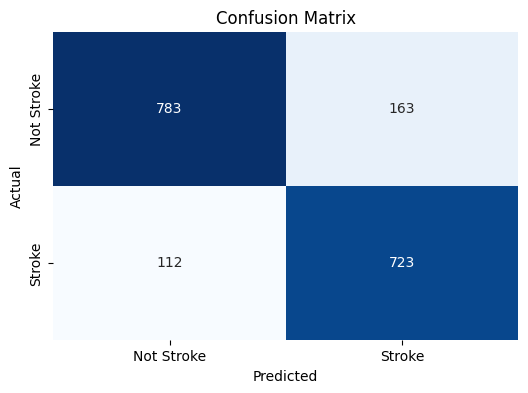


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.87      0.83      0.85       946
      Stroke       0.82      0.87      0.84       835

    accuracy                           0.85      1781
   macro avg       0.85      0.85      0.85      1781
weighted avg       0.85      0.85      0.85      1781

ROC-AUC: 0.9166196148928358


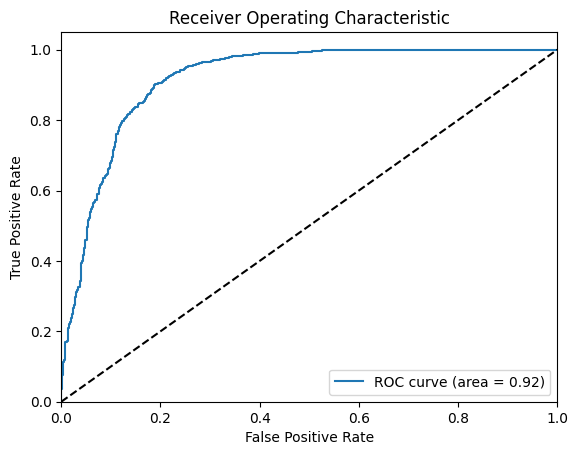

PR AUC: 0.8786785886764407


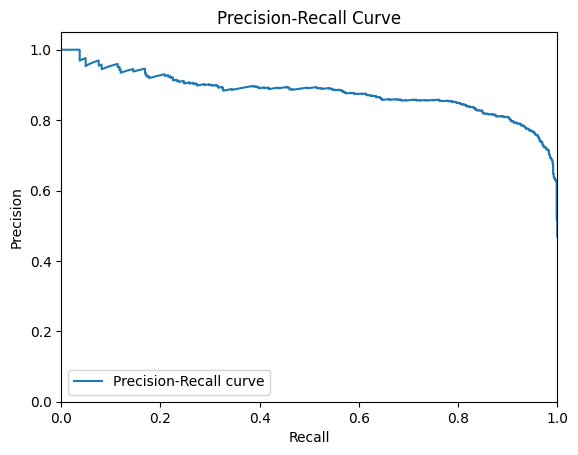

 85%|████████▍ | 11/13 [00:34<00:03,  1.57s/it]


Confusion Matrix:
 [[792 154]
 [ 96 739]]


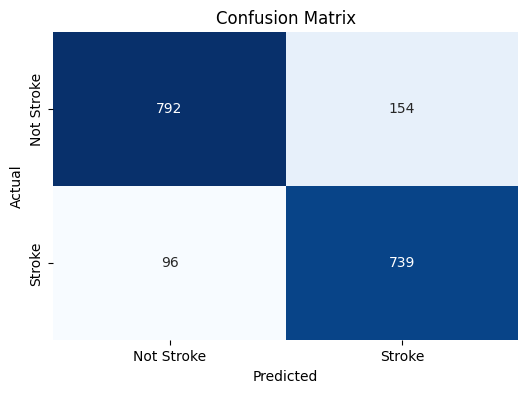


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.89      0.84      0.86       946
      Stroke       0.83      0.89      0.86       835

    accuracy                           0.86      1781
   macro avg       0.86      0.86      0.86      1781
weighted avg       0.86      0.86      0.86      1781

ROC-AUC: 0.9297590864782064


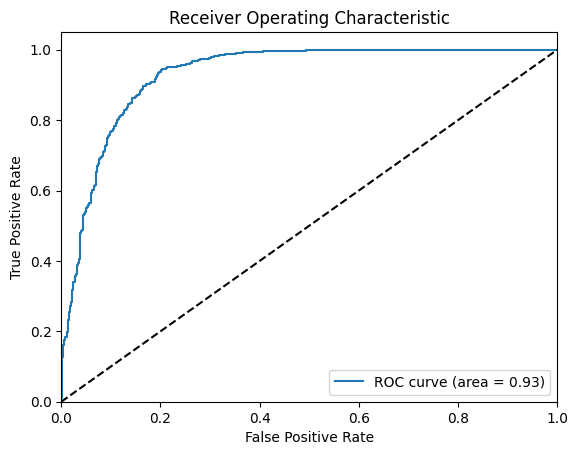

PR AUC: 0.897935877007279


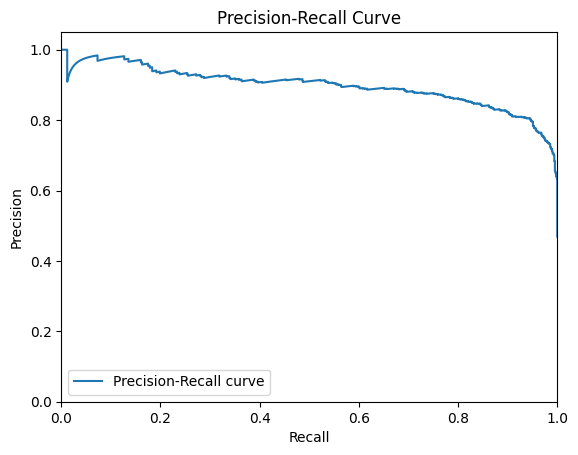

 92%|█████████▏| 12/13 [00:38<00:02,  2.27s/it]

[LightGBM] [Info] Number of positive: 3395, number of negative: 3727
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.004093 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 990
[LightGBM] [Info] Number of data points in the train set: 7122, number of used features: 42
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.476692 -> initscore=-0.093300
[LightGBM] [Info] Start training from score -0.093300

Confusion Matrix:
 [[791 155]
 [ 94 741]]


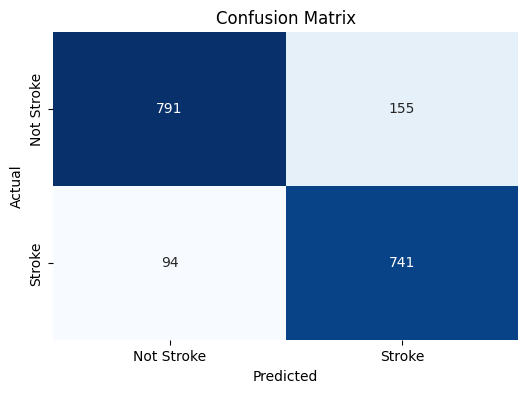


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.89      0.84      0.86       946
      Stroke       0.83      0.89      0.86       835

    accuracy                           0.86      1781
   macro avg       0.86      0.86      0.86      1781
weighted avg       0.86      0.86      0.86      1781

ROC-AUC: 0.9251079236875088


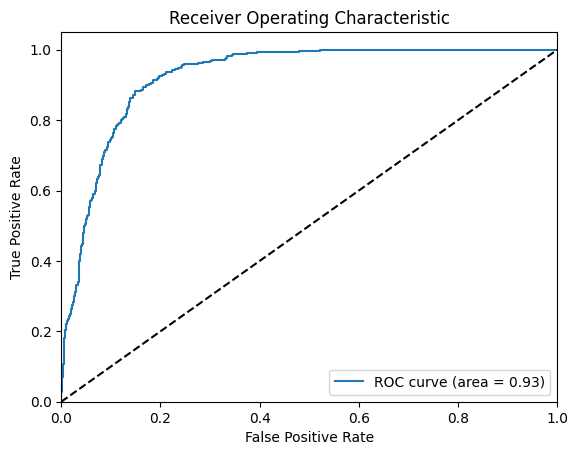

PR AUC: 0.8914082449803574


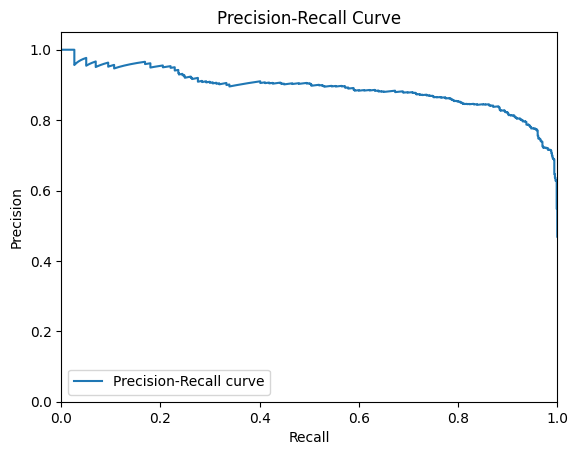

100%|██████████| 13/13 [00:39<00:00,  3.03s/it]


In [31]:
results = {}

for name, model in tqdm(models.items()):
    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    test_pred  = model.predict(X_test)



    cm = confusion_matrix(y_test, test_pred)
    print("\nConfusion Matrix:\n", cm)

    plt.figure(figsize=(6,4))
    sns.heatmap(cm,annot=True,fmt="d",cmap='Blues',cbar=False,
                xticklabels=['Not Stroke','Stroke']
                ,yticklabels=['Not Stroke','Stroke'])
    plt.ylabel('Actual')
    plt.xlabel('Predicted')
    plt.title('Confusion Matrix')
    plt.show()

    # Full classification report
    print("\nClassification Report:\n")
    print(classification_report(y_test, test_pred,target_names=['Not Stroke','Stroke'],zero_division=0))

    y_pred_prob = model.predict_proba(X_test)[:, 1]
    roc_auc = roc_auc_score(y_test, y_pred_prob)
    print("ROC-AUC:", roc_auc)

    # ROC curve
    fpr, tpr, roc_thresholds = roc_curve(y_test, y_pred_prob)
    plt.figure()
    plt.plot(fpr, tpr, label='ROC curve (area = {:.2f})'.format(roc_auc))
    plt.plot([0, 1], [0, 1], 'k--')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Receiver Operating Characteristic')
    plt.legend(loc="lower right")
    plt.show()

    pr_auc = average_precision_score(y_test, y_pred_prob)
    print("PR AUC:", pr_auc)

    precision_vals, recall_vals, pr_thresholds = precision_recall_curve(y_test, y_pred_prob)
    plt.figure()
    plt.plot(recall_vals, precision_vals, label='Precision-Recall curve')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('Recall')
    plt.ylabel('Precision')
    plt.title('Precision-Recall Curve')
    plt.legend(loc="lower left")
    plt.show()

    results[name] = {
        "Train Accuracy": accuracy_score(y_train, train_pred),
        "Test Accuracy": accuracy_score(y_test, test_pred),
        "Train Precision": precision_score(y_train, train_pred),
        "Test Precision": precision_score(y_test, test_pred),
        "Train Recall": recall_score(y_train, train_pred),
        "Test Recall": recall_score(y_test, test_pred),
        "Train F1 Score": f1_score(y_train, train_pred),
        "Test F1 Score": f1_score(y_test, test_pred),
        "Train Balanced Accuracy": balanced_accuracy_score(y_train, train_pred),
        "Test Balanced Accuracy": balanced_accuracy_score(y_test, test_pred),
        "ROC-AUC": roc_auc,
        "PR AUC": pr_auc

    }

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [15:25:19] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)



Confusion Matrix:
 [[813 133]
 [163 672]]


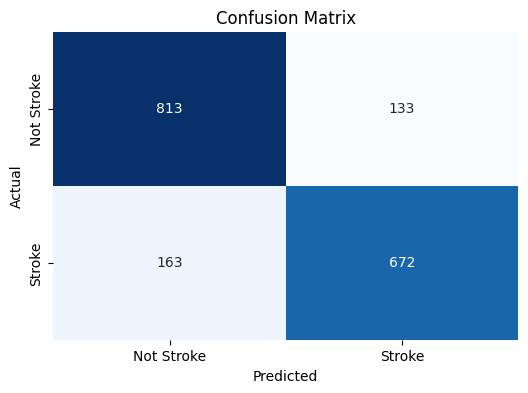


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.83      0.86      0.85       946
      Stroke       0.83      0.80      0.82       835

    accuracy                           0.83      1781
   macro avg       0.83      0.83      0.83      1781
weighted avg       0.83      0.83      0.83      1781

ROC-AUC: 0.9183020850476636


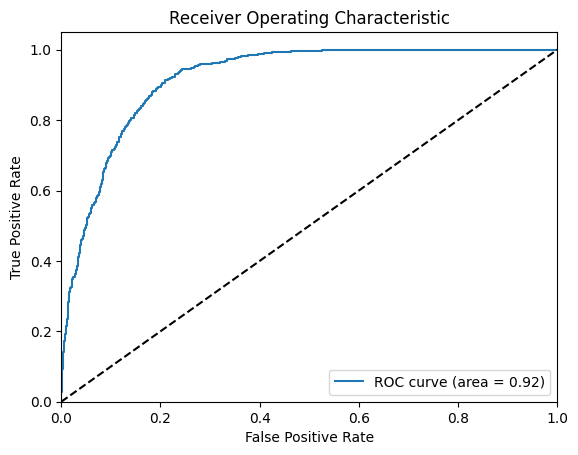

PR AUC: 0.8889528645243152


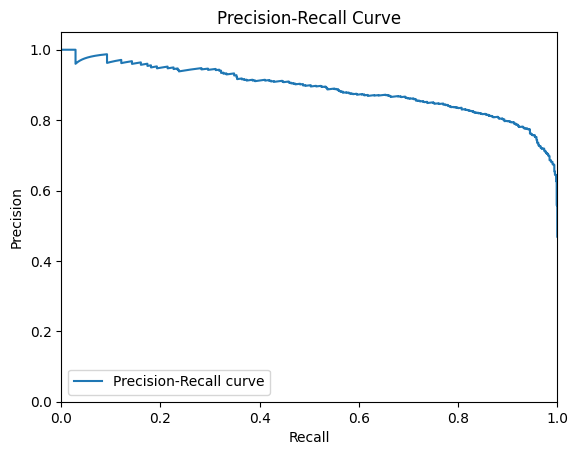

In [32]:
voting_model = VotingClassifier(
    estimators=[
        ("lr", models["Logistic Regression"]),
        ("rf", models["Random Forest"]),
        ("nb", models["Naive Bayes"]),
        ("xgb", models["XGBoost"]),
    ],
    voting="soft" # voting='hard' / voting='soft', weights=[2, 1, 2,1]
)

voting_model.fit(X_train, y_train)
voting_train_pred = voting_model.predict(X_train)
voting_test_pred = voting_model.predict(X_test)


cm = confusion_matrix(y_test, voting_test_pred)
print("\nConfusion Matrix:\n", cm)

plt.figure(figsize=(6,4))
sns.heatmap(cm,annot=True,fmt="d",cmap='Blues',cbar=False,
             xticklabels=['Not Stroke','Stroke']
            ,yticklabels=['Not Stroke','Stroke'])
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.title('Confusion Matrix')
plt.show()

# Full classification report
print("\nClassification Report:\n")
print(classification_report(y_test, voting_test_pred,target_names=['Not Stroke','Stroke'],zero_division=0))

y_pred_prob = voting_model.predict_proba(X_test)[:, 1]
roc_auc = roc_auc_score(y_test, y_pred_prob)
print("ROC-AUC:", roc_auc)

# ROC curve
fpr, tpr, roc_thresholds = roc_curve(y_test, y_pred_prob)
plt.figure()
plt.plot(fpr, tpr, label='ROC curve (area = {:.2f})'.format(roc_auc))
plt.plot([0, 1], [0, 1], 'k--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.show()

pr_auc = average_precision_score(y_test, y_pred_prob)
print("PR AUC:", pr_auc)

precision_vals, recall_vals, pr_thresholds = precision_recall_curve(y_test, y_pred_prob)
plt.figure()
plt.plot(recall_vals, precision_vals, label='Precision-Recall curve')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend(loc="lower left")
plt.show()

results["Voting Classifier"] = {
    "Train Accuracy": accuracy_score(y_train, voting_train_pred),
    "Test Accuracy": accuracy_score(y_test, voting_test_pred),
    "Train Precision": precision_score(y_train, voting_train_pred),
    "Test Precision": precision_score(y_test, voting_test_pred),
    "Train Recall": recall_score(y_train, voting_train_pred),
    "Test Recall": recall_score(y_test, voting_test_pred),
    "Train F1 Score": f1_score(y_train, voting_train_pred),
    "Test F1 Score": f1_score(y_test, voting_test_pred),
    "Train Balanced Accuracy": balanced_accuracy_score(y_train, voting_train_pred),
    "Test Balanced Accuracy": balanced_accuracy_score(y_test, voting_test_pred),
    "ROC-AUC": roc_auc,
    "PR AUC": pr_auc
}

/usr/local/lib/python3.13/dist-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [15:27:22] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "max_iter" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)



Confusion Matrix:
 [[779 167]
 [ 85 750]]


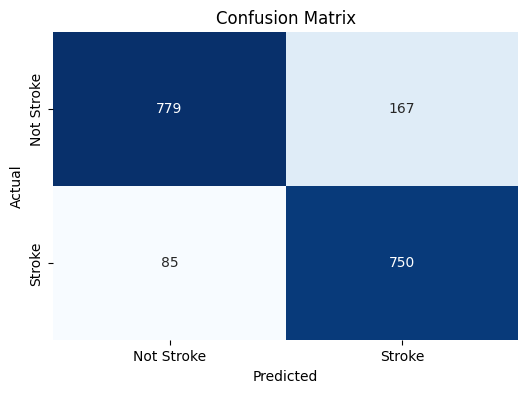


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.90      0.82      0.86       946
      Stroke       0.82      0.90      0.86       835

    accuracy                           0.86      1781
   macro avg       0.86      0.86      0.86      1781
weighted avg       0.86      0.86      0.86      1781

ROC-AUC: 0.915702421794888


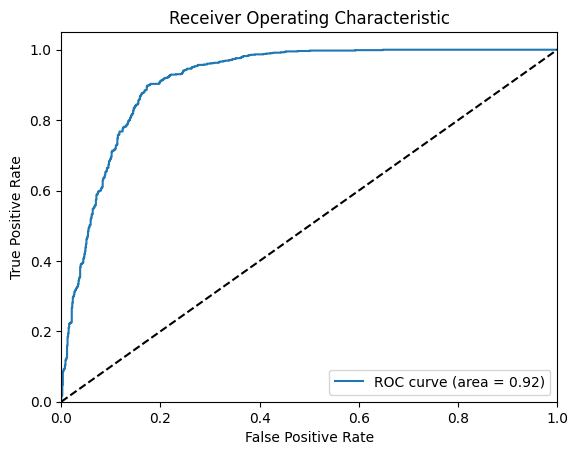

PR AUC: 0.8738324938318272


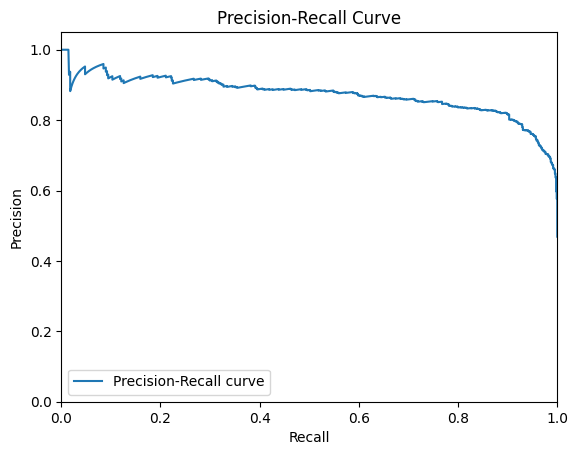

In [33]:
stack_auto = StackingClassifier(
    estimators=[
        ("lr", models["Logistic Regression"]),
        ("rf", models["Random Forest"]),
        ("nb", models["Naive Bayes"]),
        ("lgbm", models["LightGBM"]),


    ],
    final_estimator=XGBClassifier(max_iter=2000),
    stack_method="predict_proba",   # best for classification usually
    n_jobs=-1
)

# Train
stack_auto.fit(X_train, y_train)

# Predictions
stack_auto_train_pred = stack_auto.predict(X_train)
stack_auto_test_pred  = stack_auto.predict(X_test)

cm = confusion_matrix(y_test, stack_auto_test_pred)
print("\nConfusion Matrix:\n", cm)

plt.figure(figsize=(6,4))
sns.heatmap(cm,annot=True,fmt="d",cmap='Blues',cbar=False,
             xticklabels=['Not Stroke','Stroke']
            ,yticklabels=['Not Stroke','Stroke'])
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.title('Confusion Matrix')
plt.show()

# Full classification report
print("\nClassification Report:\n")
print(classification_report(y_test, stack_auto_test_pred,target_names=['Not Stroke','Stroke'],zero_division=0))

y_pred_prob = stack_auto.predict_proba(X_test)[:, 1]
roc_auc = roc_auc_score(y_test, y_pred_prob)
print("ROC-AUC:", roc_auc)

# ROC curve
fpr, tpr, roc_thresholds = roc_curve(y_test, y_pred_prob)
plt.figure()
plt.plot(fpr, tpr, label='ROC curve (area = {:.2f})'.format(roc_auc))
plt.plot([0, 1], [0, 1], 'k--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.show()

pr_auc = average_precision_score(y_test, y_pred_prob)
print("PR AUC:", pr_auc)

precision_vals, recall_vals, pr_thresholds = precision_recall_curve(y_test, y_pred_prob)
plt.figure()
plt.plot(recall_vals, precision_vals, label='Precision-Recall curve')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend(loc="lower left")
plt.show()

results["Stacking Classifier "] = {
    "Train Accuracy": accuracy_score(y_train, stack_auto_train_pred),
    "Test Accuracy": accuracy_score(y_test, stack_auto_test_pred),
    "Train Precision": precision_score(y_train, stack_auto_train_pred),
    "Test Precision": precision_score(y_test, stack_auto_test_pred),
    "Train Recall": recall_score(y_train, stack_auto_train_pred),
    "Test Recall": recall_score(y_test, stack_auto_test_pred),
    "Train F1 Score": f1_score(y_train, stack_auto_train_pred),
    "Test F1 Score": f1_score(y_test, stack_auto_test_pred),
    "Train Balanced Accuracy": balanced_accuracy_score(y_train, stack_auto_train_pred),
    "Test Balanced Accuracy": balanced_accuracy_score(y_test, stack_auto_test_pred),
    "ROC-AUC": roc_auc,
    "PR AUC": pr_auc
}

In [34]:
results_df = pd.DataFrame(results).T
results_df = results_df.sort_values(by="Test F1 Score", ascending=False)

In [35]:
results_df

,Train Accuracy,Test Accuracy,Train Precision,Test Precision,Train Recall,Test Recall,Train F1 Score,Test F1 Score,Train Balanced Accuracy,Test Balanced Accuracy,ROC-AUC,PR AUC
Stacking Classifier,0.905504,0.858506,0.877846,0.817884,0.931370,0.898204,0.903816,0.856164,0.906656,0.860835,0.915702,0.873832
Hist Gradient Boosting,0.914912,0.860191,0.886395,0.827009,0.942268,0.887425,0.913478,0.856153,0.916130,0.861789,0.925947,0.894728
LightGBM,0.915473,0.860191,0.888240,0.827009,0.941090,0.887425,0.913902,0.856153,0.916614,0.861789,0.925108,0.891408
CatBoost,0.911542,0.859629,0.891976,0.827548,0.926657,0.885030,0.908986,0.855324,0.912215,0.861120,0.929759,0.897936
Random Forest,1.000000,0.852892,1.000000,0.820112,1.000000,0.879042,1.000000,0.848555,1.000000,0.854426,0.920266,0.888499
XGBoost,0.973041,0.845592,0.962728,0.816027,0.981443,0.865868,0.971995,0.840209,0.973416,0.846782,0.916620,0.878679
Gradient Boosting,0.860292,0.841662,0.837838,0.814562,0.876583,0.857485,0.856773,0.835473,0.861018,0.842590,0.916723,0.887866
Extra Trees,1.000000,0.829871,1.000000,0.805046,1.000000,0.840719,1.000000,0.822496,1.000000,0.830507,0.901663,0.855876
Voting Classifier,0.922213,0.833801,0.926193,0.834783,0.909278,0.804790,0.917658,0.819512,0.921637,0.832099,0.918302,0.888953
Logistic Regression,0.827296,0.830994,0.832974,0.826406,0.797644,0.809581,0.814926,0.817907,0.825975,0.829738,0.904299,0.870494


<Axes: >

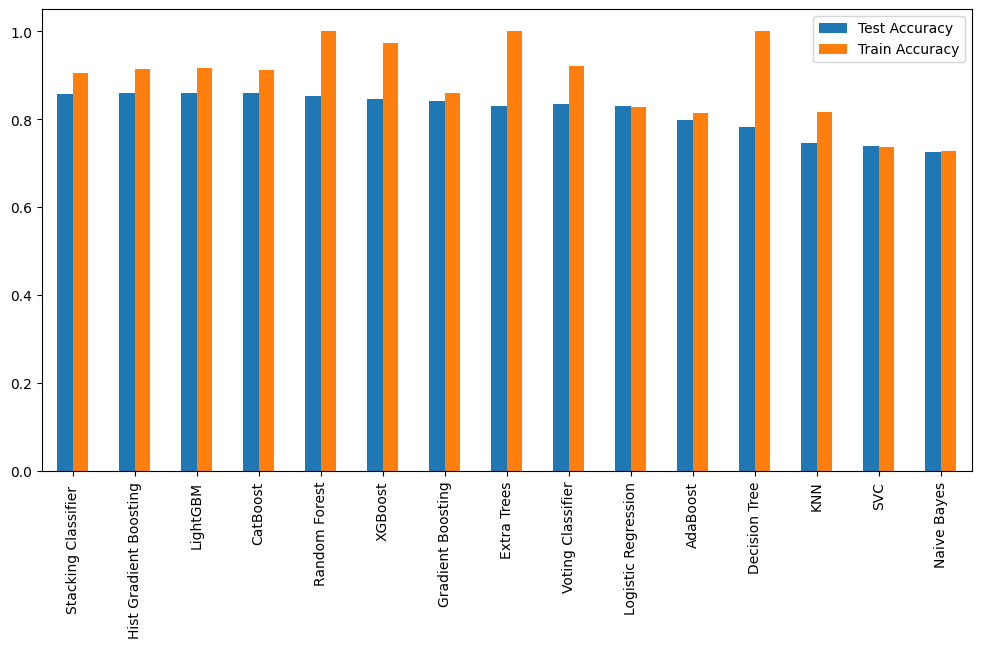

In [36]:
results_df[["Test Accuracy", "Train Accuracy"]].plot.bar(figsize=(12,6))

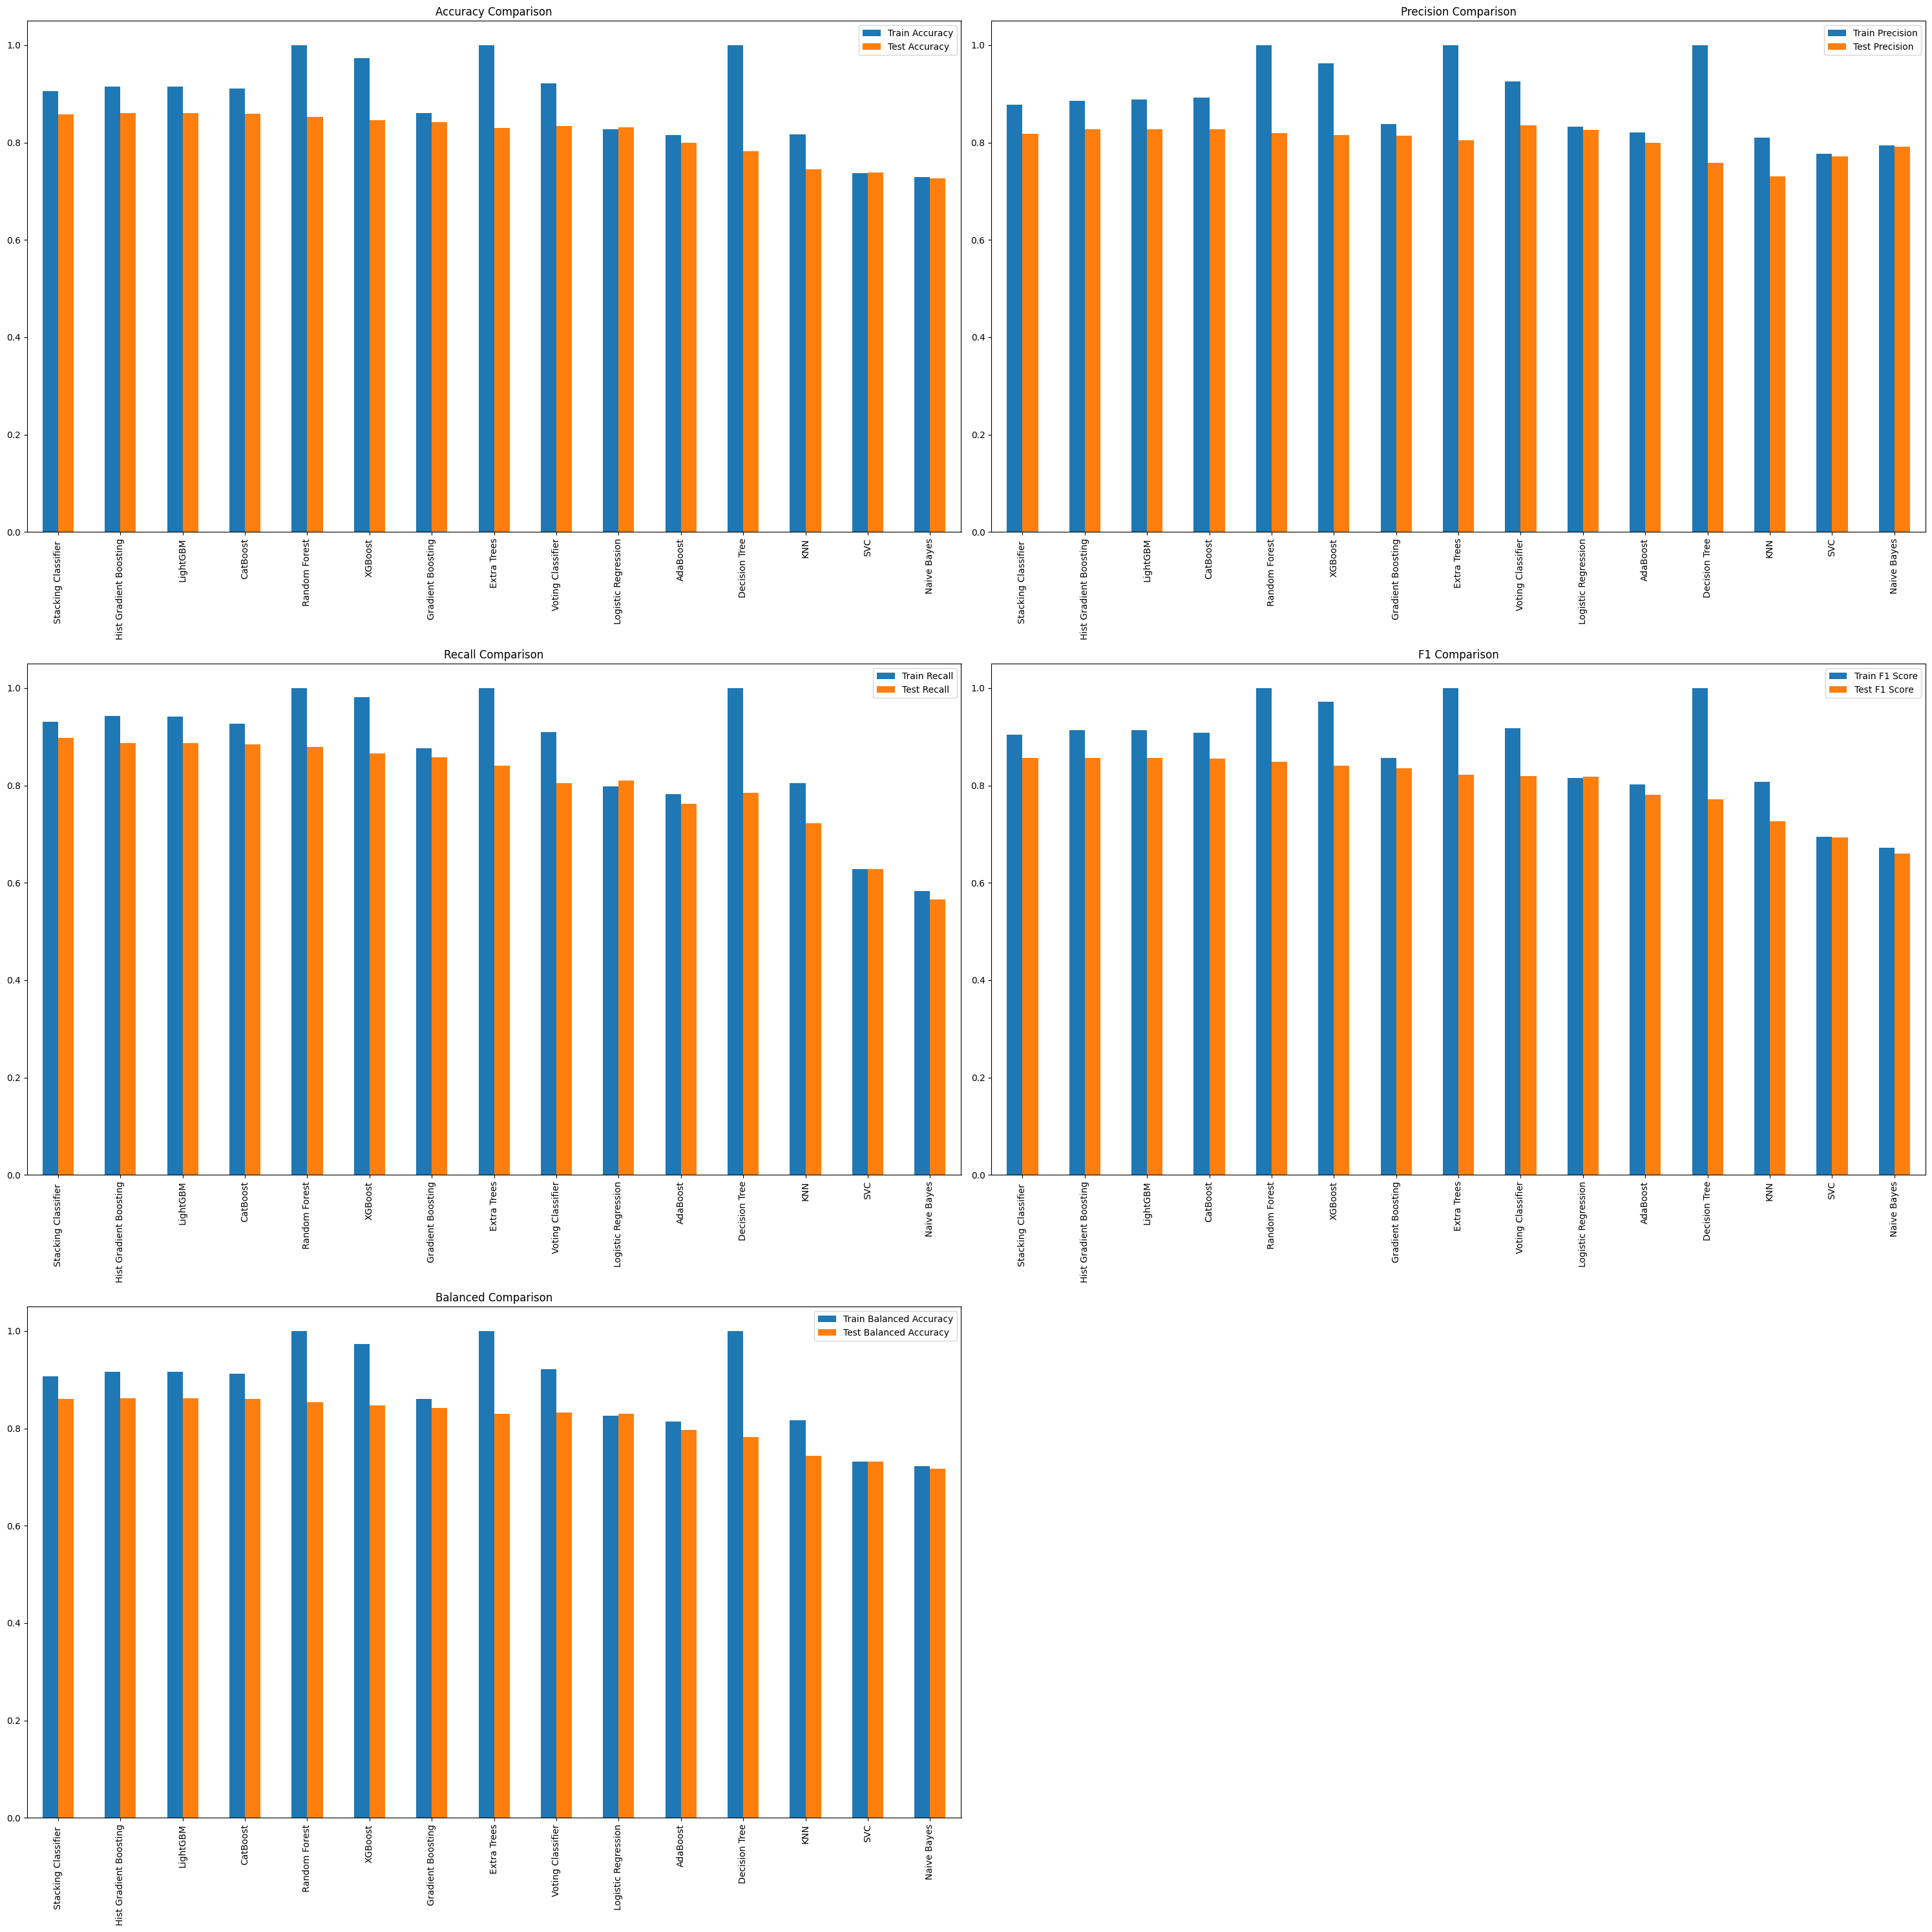

In [37]:
cols = [
    ['Train Accuracy', 'Test Accuracy'],
    ['Train Precision', 'Test Precision'],
    ['Train Recall', 'Test Recall'],
    ['Train F1 Score', 'Test F1 Score'],
    ["Train Balanced Accuracy", "Test Balanced Accuracy"]
]

plt.figure(figsize=(30,30))

for i, col in enumerate(cols):
    ax = plt.subplot(3, 2, i+1)
    results_df[col].plot.bar(ax=ax)
    ax.set_title(col[0].split(" ")[1] + ' Comparison')

plt.tight_layout()
plt.show()

In [38]:
import gradio as gr

job_choices = sorted(X['job'].unique())
marital_choices = sorted(X['marital'].unique())
education_choices = sorted(X['education'].unique())
yes_no = ['no', 'yes']
contact_choices = sorted(X['contact'].unique())
month_choices = ['jan', 'feb', 'mar', 'apr', 'may', 'jun', 'jul', 'aug', 'sep', 'oct', 'nov', 'dec']
poutcome_choices = sorted(X['poutcome'].unique())


def predict_deposit(age, job, marital, education, default, balance, housing, loan,
                    contact, day, month, duration, campaign, pdays, previous, poutcome):
    numbers = [age, balance, day, duration, campaign, pdays, previous]
    if any(v is None for v in numbers):
        return ""


    input_data = pd.DataFrame([[
        age, job, marital, education, default, balance, housing, loan,
        contact, day, month, duration, campaign, pdays, previous, poutcome
    ]], columns=X.columns)


    input_encoded = pd.get_dummies(input_data, columns=cat_cols)
    input_encoded = input_encoded.reindex(columns=X_encoded.columns, fill_value=0).astype(float)

    input_scaled = scaler.transform(input_encoded)
    prediction = best_svc.predict(input_scaled)[0]

    return "Yes (Will Subscribe)" if prediction == 1 else "No (Will Not Subscribe)"


demo = gr.Interface(
    fn=predict_deposit,
    inputs=[
        gr.Number(label="Age", value=59, precision=0),
        gr.Dropdown(job_choices, label="Job", value="admin."),
        gr.Dropdown(marital_choices, label="Marital", value="married"),
        gr.Dropdown(education_choices, label="Education", value="secondary"),
        gr.Dropdown(yes_no, label="Default", value="no"),
        gr.Number(label="Balance", value=2343),
        gr.Dropdown(yes_no, label="Housing", value="yes"),
        gr.Dropdown(yes_no, label="Loan", value="no"),
        gr.Dropdown(contact_choices, label="Contact", value="unknown"),
        gr.Number(label="Day", value=5, precision=0),
        gr.Dropdown(month_choices, label="Month", value="may"),
        gr.Number(label="Duration", value=1042),
        gr.Number(label="Campaign", value=1, precision=0),
        gr.Number(label="Pdays", value=-1, precision=0),
        gr.Number(label="Previous", value=0, precision=0),
        gr.Dropdown(poutcome_choices, label="Poutcome", value="unknown"),
    ],
    outputs=gr.Textbox(label="Prediction Result"),
    title="Bank Deposit Prediction App",
    description="Enter client details to predict whether they will subscribe to a term deposit.",
)

demo.launch()


It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://4fb66b5a57a37261c5.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
